# 05 · Ampliaciones (material para casa)

Este módulo no entra en las tres horas del taller. Son las cuatro piezas que pedirás
**el lunes**, cuando intentes usar esto en algo real:

1. **Persistencia**: que la memoria sobreviva al reinicio.
2. **Streaming**: responder mientras el modelo escribe.
3. **Supervisión**: varios especialistas coordinados (el rol, a escala).
4. **Middleware**: resumir el historial, reintentos, filtros.

Al final tienes el reto integrador y la rúbrica de evaluación.

## 5.1 Persistencia: memoria en disco

`InMemorySaver` es estupendo para clase y **pésimo** para producción: al reiniciar el
proceso, adiós conversaciones. Se cambia por un `checkpointer` que escribe en SQLite.
Ni una línea más de código: es el mismo grafo.

Lo interesante didácticamente es **ver el fichero**. Así se entiende que «tener memoria»
significa, literalmente, tener filas en una base de datos.

In [1]:
import os
import sqlite3
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.sqlite import SqliteSaver
from langchain_core.messages import SystemMessage
import comun

modelo = comun.llm()
RUTA = "memoria_seminario.db"

if os.path.exists(RUTA):
    os.remove(RUTA)                      # empezamos de cero para ver el efecto

conexion = sqlite3.connect(RUTA, check_same_thread=False)
checkpointer = SqliteSaver(conexion)

def nodo(estado: MessagesState):
    mensajes = [SystemMessage(content="Eres un chef conciso.")] + estado["messages"]
    return {"messages": [modelo.invoke(mensajes)]}

c = StateGraph(MessagesState)
c.add_node("agente", nodo)
c.add_edge(START, "agente")
c.add_edge("agente", END)

grafo_disco = c.compile(checkpointer=checkpointer)   # <-- unica diferencia
cfg = {"configurable": {"thread_id": "persistente-1"}}

grafo_disco.invoke({"messages": [{"role": "user", "content": "Me llamo Luis y me gusta el arroz."}]}, config=cfg)
respuesta = grafo_disco.invoke({"messages": [{"role": "user", "content": "¿Cómo me llamo?"}]}, config=cfg)
print("Respuesta:", respuesta["messages"][-1].content[:200])

print()
print("Y aquí está la memoria, en disco:")
tablas = [f[0] for f in conexion.execute("SELECT name FROM sqlite_master WHERE type='table'")]
print("  tablas          :", tablas)
filas = conexion.execute("SELECT count(*) FROM checkpoints").fetchone()[0]
print("  filas guardadas :", filas)
print("  tamaño fichero  :", os.path.getsize(RUTA), "bytes")


Respuesta: Te llamas Luis.

Y aquí está la memoria, en disco:
  tablas          : ['checkpoints', 'writes']
  filas guardadas : 6
  tamaño fichero  : 4096 bytes


Ese fichero es la conversación. Si cierras el cuaderno, reinicias el kernel y vuelves a
abrir la misma base de datos con el **mismo `thread_id`**, el hilo continúa donde estaba.

**Aviso de concurrencia:** SQLite va bien en clase y para un usuario. Con varios usuarios
simultáneos necesitarás PostgreSQL (`langgraph-checkpoint-postgres`). Y recuerda que el
`Store` de largo plazo es **otro** almacén: se persiste por separado
(`langgraph.store.postgres.PostgresStore`), y es un fallo clásico persistir uno y olvidar
el otro.

## 5.2 Streaming: no hacer esperar al usuario

Hasta ahora hemos usado `invoke`, que devuelve la respuesta completa. En una interfaz real
quieres ver las palabras aparecer. `stream_events` da proyecciones tipadas: mensajes,
valores, subgrafos e interrupciones.

In [2]:
peticion = {"messages": [{"role": "user", "content": "Explica en tres frases qué es un agente."}]}

flujo = grafo_disco.stream_events(peticion, config={"configurable": {"thread_id": "stream-1"}}, version="v3")

print("Llegando en directo:")
for mensaje in flujo.messages:
    for trozo in mensaje.text:
        print(trozo, end="", flush=True)
print()


Llegando en directo:


/home/luis/Descargas/langGraph/seminario/.venv/lib/python3.12/site-packages/langgraph/pregel/main.py:3708: LangChainBetaWarning: The v3 streaming protocol on Pregel is experimental.
  return self._pregel_stream_v3(
/home/luis/Descargas/langGraph/seminario/.venv/lib/python3.12/site-packages/langgraph/pregel/main.py:3558: LangChainBetaWarning: The v3 streaming protocol on Pregel is experimental.
  return GraphRunStream(graph_iter, mux)


Un

 agente

 es

...

 para

 modificar

 dicho

 entorno

.

Verás un `LangChainBetaWarning`: la API de eventos v3 todavía está marcada como
experimental. Es la recomendada en la documentación, pero conviene saberlo antes de
construir producción encima. La alternativa estable es `stream(..., stream_mode=[...],
version="v2")`.

**Consecuencia didáctica:** si usas streaming, tu agente tarda lo mismo pero *parece*
mucho más rápido. Es la mejora de experiencia de usuario más barata que existe.

## 5.3 Supervisión: el rol, a escala

Ya sabemos dar un rol a un agente. Un sistema multiagente es la misma idea repetida:
varios especialistas y **alguien que decide a quién preguntar**. Ese alguien es el
supervisor, y su decisión también es salida estructurada.

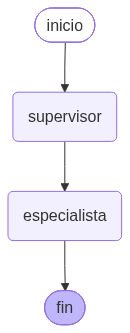

---
config:
 flowchart:
  curve: linear
---
graph TD;
	__start__([inicio]):::first
	supervisor(supervisor)
	especialista(especialista)
	__end__([fin]):::last
	__start__ --> supervisor;
	supervisor --> especialista;
	especialista --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc


[grafo] Grafo 5: supervisor + especialista  ·  guardado en grafos/grafo-5-supervisor-especialista.mmd


In [3]:
from typing import Annotated, Literal
from typing_extensions import TypedDict
import operator
from pydantic import BaseModel, Field
from langchain_core.messages import SystemMessage
from langgraph.graph import StateGraph, START, END

ESPECIALISTAS = {
    "chef": "Eres un chef mediterráneo. Propones platos sabrosos y rápidos.",
    "nutricionista": "Eres un nutricionista deportivo. Das cifras de calorías y macros.",
    "comprador": "Eres un experto en precios de supermercado. Hablas de costes y ahorro.",
}

class Decision(BaseModel):
    especialista: Literal["chef", "nutricionista", "comprador"] = Field(
        description="El especialista más adecuado para responder"
    )
    motivo: str = Field(description="Por qué ese y no otro")

class EstadoEquipo(TypedDict):
    peticion: str
    especialista: str
    motivo: str
    respuesta: str

enrutador = modelo.with_structured_output(Decision, method="function_calling")

def nodo_supervisor(estado: EstadoEquipo):
    decision = enrutador.invoke(
        "Elige al especialista más adecuado para esta petición: " + estado["peticion"]
    )
    print(f"SUPERVISOR -> {decision.especialista}  ({decision.motivo})")
    return {"especialista": decision.especialista, "motivo": decision.motivo}

def nodo_especialista(estado: EstadoEquipo):
    sistema = SystemMessage(content=ESPECIALISTAS[estado["especialista"]])
    respuesta = modelo.invoke([sistema, ("human", estado["peticion"])])
    return {"respuesta": respuesta.content}

g = StateGraph(EstadoEquipo)
g.add_node("supervisor", nodo_supervisor)
g.add_node("especialista", nodo_especialista)
g.add_edge(START, "supervisor")
g.add_edge("supervisor", "especialista")
g.add_edge("especialista", END)
equipo = g.compile()

comun.ver_grafo(equipo, "Grafo 5: supervisor + especialista")


In [4]:
for pregunta in [
    "¿Cuántas calorías tiene el pollo con arroz?",
    "¿Qué me cuesta la cena para cuatro?",
    "Quiero un plato resultón y rápido con lo que tengo.",
]:
    salida = equipo.invoke({"peticion": pregunta})
    print("PREGUNTA:", pregunta)
    print("RESPUESTA:", salida["respuesta"][:220].replace("\n", " "))
    print("-" * 70)


SUPERVISOR -> nutricionista  (El usuario solicita información nutricional específica (conteo de calorías), lo cual es la especialidad de un nutricionista.)


PREGUNTA: ¿Cuántas calorías tiene el pollo con arroz?
RESPUESTA: Como nutricionista deportivo, lo primero que debo aclararte es que el valor nutricional **depende totalmente de las cantidades, el método de cocción y los acompañamientos**. No es lo mismo un pollo al horno con arroz bla
----------------------------------------------------------------------


SUPERVISOR -> comprador  (La pregunta se refiere específicamente al costo económico de los ingredientes o del servicio, lo cual es competencia de alguien encargado de las compras y el presupuesto.)


PREGUNTA: ¿Qué me cuesta la cena para cuatro?
RESPUESTA: Para darte un presupuesto exacto, necesitaría saber qué tienes en mente (¿una cena rápida, algo saludable o una ocasión especial?), pero como experto en costes, voy a desglosarte **tres escenarios típicos** basados en pr
----------------------------------------------------------------------


SUPERVISOR -> chef  (El usuario busca una preparación culinaria que sea visualmente atractiva ('resultón') y eficiente en tiempo ('rápido'), competencias principales de un chef.)


PREGUNTA: Quiero un plato resultón y rápido con lo que tengo.
RESPUESTA: ¡Hola! Aquí tienes a tu chef. Para poder darte la receta exacta, **necesito que me digas qué tienes en la nevera y en la despensa**.   Sin embargo, mientras me escribes la lista, te propongo **tres "comodines" mediterrán
----------------------------------------------------------------------


Este equipo es de un solo turno: el supervisor elige y el especialista responde. Convertirlo
en un equipo que **itera** es un ejercicio de diez minutos con lo que ya sabes:

1. añade `"FIN"` a los valores posibles de `especialista`,
2. apunta las respuestas en una lista del estado (`Annotated[list, operator.add]`),
3. cambia la arista `especialista -> END` por `especialista -> supervisor`,
4. añade una arista condicional que vaya a `END` cuando el supervisor diga `"FIN"`,
5. pon un `recursion_limit` bajo (por ejemplo 12) para que no se desboque.

Ese es el patrón «supervisor» completo, y lo has construido tú.

## 5.4 Middleware: lo que no hemos escondido

LangChain 1.x trae *middleware* para los problemas transversales de cualquier agente. Los
tres que necesitarás primero:

| Middleware | Problema que resuelve |
|---|---|
| `SummarizationMiddleware` | el historial crece sin límite y se come el contexto |
| `HumanInTheLoopMiddleware` | aprobar herramientas peligrosas antes de ejecutarlas |
| `PIIMiddleware` | no dejar que datos personales acaben en el modelo |

```python
from langchain.agents.middleware import SummarizationMiddleware

agente = create_agent(
    modelo, tools=HERRAMIENTAS,
    middleware=[SummarizationMiddleware(model=modelo, max_tokens_before_summary=4000)],
)
```

Los hemos dejado fuera a propósito: **primero la mecánica, después el atajo**. Si hubiéramos
empezado por aquí, no sabrías qué se está resumiendo ni por qué.

---

## Reto integrador (para casa o para evaluar)

Construye un **asistente de cocina con memoria y supervisión** que cumpla:

1. **Rol diferenciado.** Al menos dos roles con objetivos distintos y verificables.
2. **Herramientas.** Al menos tres, una de ellas con un modo de fallo controlado
   (`handle_tool_errors`) y un docstring que explique bien cuándo usarla.
3. **Memoria.** Corto plazo con `checkpointer` y largo plazo con `Store`, de modo que
   recuerde una alergia entre conversaciones distintas.
4. **Planificación.** Elige ReAct o plan-and-execute y **justifica** la elección por
   escrito, con el número de llamadas al modelo que hace cada uno en tu caso.
5. **Freno humano.** Un `interrupt()` antes de una acción con consecuencias.
6. **Verificación.** Al menos una `assert` que compruebe que el resultado cumple el
   contrato (por ejemplo, que la receta no lleva el ingrediente prohibido).

### Rúbrica

| Criterio | Insuficiente | Bien | Excelente |
|---|---|---|---|
| Rol | un prompt vago | rol con objetivo claro | rol con restricción verificada en código |
| Herramientas | devuelven datos fijos | docstrings claros y errores controlados | una herramienta consulta algo real |
| Memoria | solo `checkpointer` | corto y largo plazo funcionando | *namespaces* por usuario |
| Planificación | ReAct sin justificar | estrategia elegida y medida | compara ambas con datos |
| Freno humano | ausente | `interrupt` que funciona | con `response_schema` y aprobación del plan |
| Trazabilidad | solo la respuesta final | inspecciona `messages` | guarda trazas y las comenta |

### La pregunta que importa

Cuando entregues el reto, responde en cinco líneas:

> **¿En qué punto exacto de tu grafo tomaría una decisión equivocada el agente, y cómo te
> enterarías?**

Si sabes responder eso, has entendido el seminario. Si no, has aprendido a invocar una API.